/Users/Vanshika/Documents/NSUT/DSA/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps | models: ['efficientnet_b2', 'densenet121']
HAM10000 usable images: 10015
label
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64
train 7153 | val 1431 | test 1431  (no shared lesions)

TRAINING efficientnet_b2


/var/folders/8v/blbrt1150g38htb5ctjw2sr00000gn/T/ipykernel_80171/3013014210.py:156: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


[efficientnet_b2] ep 01/50 loss 1.6644 | val acc 0.6583 bal_acc 0.5277 | 125s *saved*
[efficientnet_b2] ep 02/50 loss 1.0225 | val acc 0.7449 bal_acc 0.5924 | 125s *saved*
[efficientnet_b2] ep 03/50 loss 0.8673 | val acc 0.7771 bal_acc 0.6491 | 120s *saved*
[efficientnet_b2] ep 04/50 loss 0.7937 | val acc 0.7966 bal_acc 0.6642 | 125s *saved*
[efficientnet_b2] ep 05/50 loss 0.7484 | val acc 0.7771 bal_acc 0.6793 | 120s *saved*
[efficientnet_b2] ep 06/50 loss 0.6929 | val acc 0.8050 bal_acc 0.6856 | 118s *saved*
[efficientnet_b2] ep 07/50 loss 0.6657 | val acc 0.8120 bal_acc 0.6974 | 118s *saved*
[efficientnet_b2] ep 08/50 loss 0.6411 | val acc 0.8148 bal_acc 0.6942 | 118s
[efficientnet_b2] ep 09/50 loss 0.6138 | val acc 0.8246 bal_acc 0.7164 | 118s *saved*
[efficientnet_b2] ep 10/50 loss 0.6034 | val acc 0.8085 bal_acc 0.6928 | 125s
[efficientnet_b2] ep 11/50 loss 0.5798 | val acc 0.8288 bal_acc 0.7176 | 117s *saved*
[efficientnet_b2] ep 12/50 loss 0.5689 | val acc 0.8232 bal_acc 0.7114

/var/folders/8v/blbrt1150g38htb5ctjw2sr00000gn/T/ipykernel_80171/3013014210.py:156: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


[densenet121] ep 01/50 loss 1.2626 | val acc 0.7820 bal_acc 0.6972 | 115s *saved*
[densenet121] ep 02/50 loss 0.9246 | val acc 0.8001 bal_acc 0.7186 | 113s *saved*
[densenet121] ep 03/50 loss 0.8394 | val acc 0.8106 bal_acc 0.7077 | 114s
[densenet121] ep 04/50 loss 0.7701 | val acc 0.8183 bal_acc 0.7323 | 114s *saved*
[densenet121] ep 05/50 loss 0.7293 | val acc 0.8148 bal_acc 0.7209 | 114s
[densenet121] ep 06/50 loss 0.6908 | val acc 0.8120 bal_acc 0.7414 | 115s *saved*
[densenet121] ep 07/50 loss 0.6619 | val acc 0.8288 bal_acc 0.7534 | 114s *saved*
[densenet121] ep 08/50 loss 0.6466 | val acc 0.8197 bal_acc 0.7354 | 114s
[densenet121] ep 09/50 loss 0.6212 | val acc 0.8071 bal_acc 0.7349 | 115s
[densenet121] ep 10/50 loss 0.6050 | val acc 0.8092 bal_acc 0.6720 | 112s
[densenet121] ep 11/50 loss 0.5873 | val acc 0.8288 bal_acc 0.7530 | 112s
[densenet121] ep 12/50 loss 0.5806 | val acc 0.8274 bal_acc 0.7263 | 112s
[densenet121] ep 13/50 loss 0.5667 | val acc 0.8204 bal_acc 0.7145 | 114

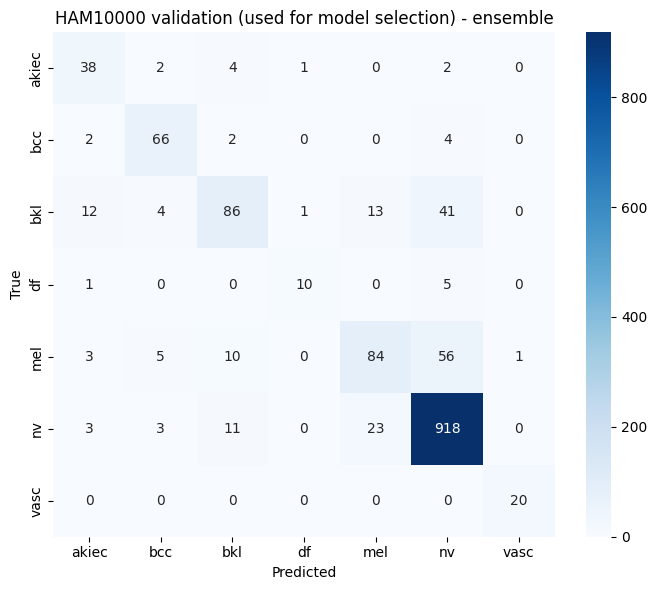

In [1]:
# ===================== CELL 1: TRAIN ON HAM10000 =====================
# pip install torch torchvision timm pandas numpy scikit-learn matplotlib seaborn pillow
# Run this notebook from inside "CV Lab Project/" (the folder that contains data/).
#
# Leakage controls:
#  * HAM10000 is split into train / val / test BY lesion_id (stratified), so the same
#    lesion never appears in two partitions.
#  * Only the train split is augmented / oversampled.
#  * Model selection (best epoch) uses val only. The ensemble is a plain average (no tuned
#    weights, multipliers or thresholds), so nothing is tuned on any test data.
#  * Test sets (cells 2 and 3) are used only for final evaluation.

import os, time, random
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix)

# ------------------------- config -------------------------
TAG = "nb3_effnet_densenet121"
MODEL_NAMES = ['efficientnet_b2', 'densenet121']          # timm model names
LR = {"swin_tiny_patch4_window7_224": 5e-5, "convnext_tiny": 5e-5}   # default 1e-4
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
NUM_CLASSES = len(CLASSES)
IMG = 224
BATCH = 32
EPOCHS = 50
PATIENCE = 10                      # early stop if val balanced acc does not improve for 10 epochs
SEED = 42

BASE = Path.cwd()
DATA = BASE / "data"
HAM_CSV = DATA / "HAM10000_metadata.csv"
HAM_IMGS = DATA / "images"
ISIC_DIR = DATA / "ISIC2019_Dataset"
MODEL_DIR = BASE / "models"; MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR = BASE / "research_results"; OUT_DIR.mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
NUM_WORKERS = 4 if DEVICE.type == "cuda" else 0
print("Device:", DEVICE, "| models:", MODEL_NAMES)

# ------------------------- data frames -------------------------
def build_ham_df():
    ham = pd.read_csv(HAM_CSV)
    paths = {p.stem: str(p) for p in HAM_IMGS.rglob("*.jpg")}
    ham = ham[ham["image_id"].isin(paths)].copy()
    ham["path"] = ham["image_id"].map(paths)
    ham["label"] = ham["dx"]
    ham["group"] = ham["lesion_id"].astype(str)
    ham["y"] = ham["label"].map({c: i for i, c in enumerate(CLASSES)})
    return ham[["image_id", "path", "label", "group", "y"]].reset_index(drop=True)

ISIC_FOLDER_TO_DX = {"AK": "akiec", "BCC": "bcc", "BKL": "bkl", "DF": "df",
                     "MEL": "mel", "NV": "nv", "VASC": "vasc"}   # SCC is not in the 7-class space

def build_isic_df():
    rows = []
    for folder, dx in ISIC_FOLDER_TO_DX.items():
        for p in (ISIC_DIR / folder).rglob("*.jpg"):
            rows.append((p.stem, str(p), dx))
    df = pd.DataFrame(rows, columns=["image_id", "path", "label"])
    df["y"] = df["label"].map({c: i for i, c in enumerate(CLASSES)})
    return df

_ISIC_CACHE = {}
def get_isic_deduped():
    # ISIC2019 contains the HAM10000 images -> remove them by image id so that no image
    # the models were trained on shows up in the ISIC test set.
    if "df" not in _ISIC_CACHE:
        isic = build_isic_df()
        n0 = len(isic)
        isic = isic[~isic["image_id"].isin(set(ham_all["image_id"]))].reset_index(drop=True)
        print(f"ISIC2019: {n0} images -> {len(isic)} after removing {n0 - len(isic)} HAM10000 duplicates")
        _ISIC_CACHE["df"] = isic
    return _ISIC_CACHE["df"]

ham_all = build_ham_df()
print("HAM10000 usable images:", len(ham_all)); print(ham_all["label"].value_counts())

# lesion-grouped, stratified 3-way split
sg1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trval_idx, test_idx = next(sg1.split(ham_all, ham_all["y"], ham_all["group"]))
trval, test_df = ham_all.iloc[trval_idx].reset_index(drop=True), ham_all.iloc[test_idx].reset_index(drop=True)
sg2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sg2.split(trval, trval["y"], trval["group"]))
train_df, val_df = trval.iloc[tr_idx].reset_index(drop=True), trval.iloc[va_idx].reset_index(drop=True)
assert not (set(train_df.group) & set(val_df.group)) and not (set(train_df.group) & set(test_df.group)) \
    and not (set(val_df.group) & set(test_df.group)), "lesion leakage!"
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}  (no shared lesions)")
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(OUT_DIR / f"{TAG}_ham_{n}_split.csv", index=False)

# ------------------------- preprocessing / datasets -------------------------
def shades_of_gray(img, p=6):          # colour constancy -> helps cross-dataset transfer
    x = np.asarray(img, dtype=np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p) + 1e-6
    illum = illum / np.linalg.norm(illum)
    x = x / (illum * np.sqrt(3.0))
    return Image.fromarray(np.clip(x, 0, 255).astype(np.uint8))

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomAffine(degrees=30, translate=(0.1, 0.1), scale=(0.85, 1.15), shear=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor()])
eval_tf = transforms.ToTensor()

class LesionDS(Dataset):
    def __init__(self, df, train):
        self.paths, self.y, self.tf = df["path"].tolist(), df["y"].values, (train_tf if train else eval_tf)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB").resize((IMG, IMG), Image.BILINEAR)
        return self.tf(shades_of_gray(img)), int(self.y[i])

counts = train_df["y"].value_counts().reindex(range(NUM_CLASSES)).values.astype(float)
sample_w = (1.0 / np.sqrt(counts))[train_df["y"].values]      # mild minority oversampling, train only
sampler = WeightedRandomSampler(sample_w, num_samples=len(train_df), replacement=True)
train_loader = DataLoader(LesionDS(train_df, True), BATCH, sampler=sampler, num_workers=NUM_WORKERS)
val_loader = DataLoader(LesionDS(val_df, False), BATCH, num_workers=NUM_WORKERS)

# ------------------------- models -------------------------
class Wrapped(nn.Module):
    # takes [0,1] images, applies each backbone's own ImageNet normalisation
    def __init__(self, name):
        super().__init__()
        self.m = timm.create_model(name, pretrained=True, num_classes=NUM_CLASSES)
        cfg = timm.data.resolve_data_config({}, model=self.m)
        self.register_buffer("mean", torch.tensor(cfg["mean"]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(cfg["std"]).view(1, 3, 1, 1))
    def forward(self, x): return self.m((x - self.mean) / self.std)

@torch.no_grad()
def predict_loader(model, loader):
    model.eval(); out = []
    for x, _ in loader:
        out.append(F.softmax(model(x.to(DEVICE)).float(), 1).cpu().numpy())
    return np.concatenate(out)

def train_model(name):
    model = Wrapped(name).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR.get(name, 1e-4), weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best, bad, ckpt = -1, 0, MODEL_DIR / f"{TAG}_{name}.pth"
    for ep in range(1, EPOCHS + 1):
        model.train(); t0, run = time.time(), 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(device_type="cuda", enabled=use_amp):
                loss = F.cross_entropy(model(x), y, label_smoothing=0.1)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * x.size(0)
        sched.step()
        pv = predict_loader(model, val_loader)
        bal = balanced_accuracy_score(val_df["y"].values, pv.argmax(1))    # selection metric (val only)
        acc = accuracy_score(val_df["y"].values, pv.argmax(1))
        flag = ""
        if bal > best:
            best, bad, flag = bal, 0, " *saved*"; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        print(f"[{name}] ep {ep:02d}/{EPOCHS} loss {run/len(train_df):.4f} | val acc {acc:.4f} bal_acc {bal:.4f} | {time.time()-t0:.0f}s{flag}")
        if bad >= PATIENCE:
            print("early stop"); break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); model.eval()
    return model

MODELS = {}
for n in MODEL_NAMES:
    print("\n" + "=" * 70 + f"\nTRAINING {n}\n" + "=" * 70)
    MODELS[n] = train_model(n)

# ------------------------- shared inference / reporting helpers -------------------------
def get_probs(df):
    loader = DataLoader(LesionDS(df, False), BATCH, num_workers=NUM_WORKERS)
    return {n: predict_loader(m, loader) for n, m in MODELS.items()}

def report(title, y, P):
    ens = np.mean([P[n] for n in MODEL_NAMES], axis=0)
    allp = dict(P); allp["ENSEMBLE (mean)"] = ens
    rows = [dict(model=n, acc=accuracy_score(y, p.argmax(1)), balanced_acc=balanced_accuracy_score(y, p.argmax(1)),
                 macro_f1=f1_score(y, p.argmax(1), average="macro", zero_division=0)) for n, p in allp.items()]
    print("\n" + "=" * 70 + f"\n{title}  (n={len(y)})\n" + "=" * 70)
    print(pd.DataFrame(rows).round(4).to_string(index=False))
    names = list(P)                     # complementarity: lower double-fault = more complementary
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            wi, wj = P[names[i]].argmax(1) != y, P[names[j]].argmax(1) != y
            print(f"double-fault {names[i]} & {names[j]}: {(wi & wj).mean():.4f} | disagreement: "
                  f"{(P[names[i]].argmax(1) != P[names[j]].argmax(1)).mean():.4f}")
    pred = ens.argmax(1)
    print("\nEnsemble classification report:")
    print(classification_report(y, pred, labels=range(NUM_CLASSES), target_names=CLASSES, digits=3, zero_division=0))
    cm = confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    plt.figure(figsize=(7, 6)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title(f"{title} - ensemble"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout()
    safe = "".join(ch if ch.isalnum() else "_" for ch in title)
    plt.savefig(OUT_DIR / f"{TAG}_{safe}_cm.png", dpi=150); plt.show()

# validation sanity check (this set is used for epoch selection, so it is NOT a test result)
PV = get_probs(val_df)
report("HAM10000 validation (used for model selection)", val_df["y"].values, PV)


ISIC2019: 24703 images -> 14885 after removing 9818 HAM10000 duplicates
label
nv       6170
mel      3409
bcc      2809
bkl      1525
akiec     737
df        124
vasc      111
Name: count, dtype: int64

ISIC2019 external test (HAM-trained)  (n=14885)
          model    acc  balanced_acc  macro_f1
efficientnet_b2 0.5855        0.4070    0.4026
    densenet121 0.5639        0.3923    0.3824
ENSEMBLE (mean) 0.5968        0.4234    0.4211
double-fault efficientnet_b2 & densenet121: 0.3250 | disagreement: 0.3125

Ensemble classification report:
              precision    recall  f1-score   support

       akiec      0.197     0.189     0.193       737
         bcc      0.795     0.335     0.471      2809
         bkl      0.374     0.410     0.392      1525
          df      0.163     0.323     0.216       124
         mel      0.621     0.439     0.515      3409
          nv      0.653     0.908     0.760      6170
        vasc      0.455     0.360     0.402       111

    accuracy        

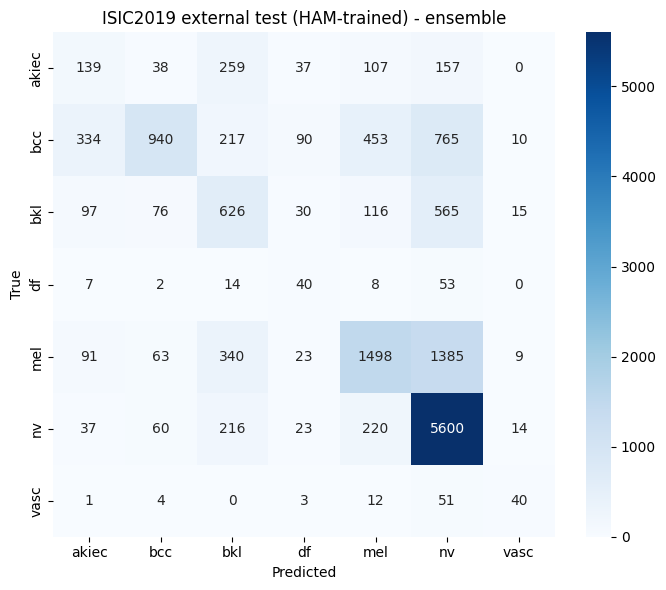

In [2]:
# ===================== CELL 2: TEST ON ISIC2019 (external dataset) =====================
# Models were trained only on the HAM10000 train split. ISIC2019 images that are also in
# HAM10000 are removed, so this is a true cross-dataset test (domain shift is expected).
isic_df = get_isic_deduped()
print(isic_df["label"].value_counts())
PROBS = globals().setdefault("PROBS", {})
PROBS["isic"] = get_probs(isic_df)
report("ISIC2019 external test (HAM-trained)", isic_df["y"].values, PROBS["isic"])



HAM10000 held-out test (in-dataset)  (n=1431)
          model    acc  balanced_acc  macro_f1
efficientnet_b2 0.8162        0.6030    0.6380
    densenet121 0.8078        0.6668    0.6873
ENSEMBLE (mean) 0.8267        0.6459    0.6815
double-fault efficientnet_b2 & densenet121: 0.1251 | disagreement: 0.1565

Ensemble classification report:
              precision    recall  f1-score   support

       akiec      0.407     0.522     0.457        46
         bcc      0.747     0.757     0.752        74
         bkl      0.774     0.522     0.624       157
          df      0.800     0.471     0.593        17
         mel      0.582     0.491     0.532       159
          nv      0.891     0.959     0.924       958
        vasc      1.000     0.800     0.889        20

    accuracy                          0.827      1431
   macro avg      0.743     0.646     0.681      1431
weighted avg      0.821     0.827     0.819      1431



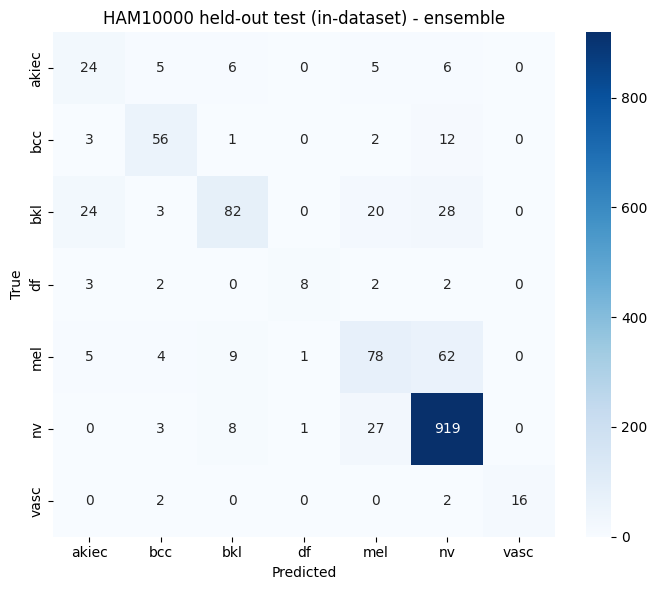


Combined HAM-test + ISIC2019  (n=16316)
          model    acc  balanced_acc  macro_f1
efficientnet_b2 0.6057        0.4251    0.4238
    densenet121 0.5853        0.4167    0.4100
ENSEMBLE (mean) 0.6169        0.4427    0.4448
double-fault efficientnet_b2 & densenet121: 0.3074 | disagreement: 0.2988

Ensemble classification report:
              precision    recall  f1-score   support

       akiec      0.213     0.208     0.211       783
         bcc      0.792     0.345     0.481      2883
         bkl      0.398     0.421     0.409      1682
          df      0.188     0.340     0.242       141
         mel      0.619     0.442     0.515      3568
          nv      0.679     0.915     0.779      7128
        vasc      0.538     0.427     0.477       131

    accuracy                          0.617     16316
   macro avg      0.489     0.443     0.445     16316
weighted avg      0.629     0.617     0.596     16316



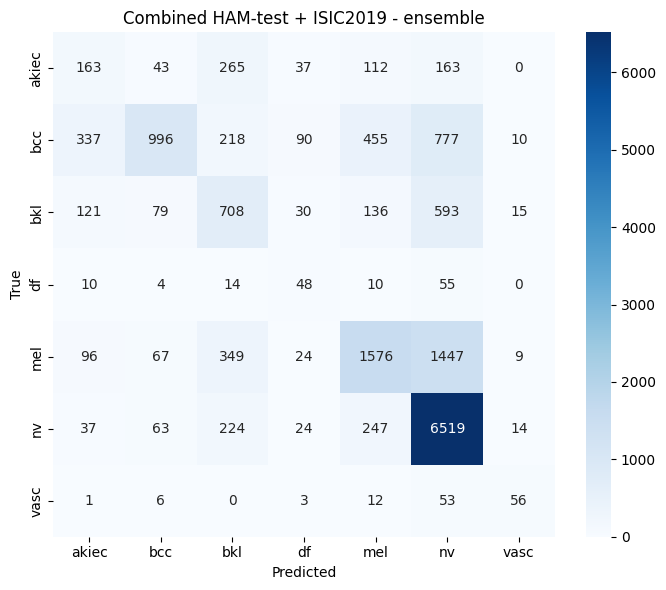

In [3]:
# ===================== CELL 3: TEST ON COMBINED (HAM10000 test split + ISIC2019) =====================
# HAM part  = held-out, lesion-disjoint test split only (never used in training/validation).
# ISIC part = ISIC2019 minus HAM10000 duplicates.
PROBS = globals().setdefault("PROBS", {})
isic_df = get_isic_deduped()
if "isic" not in PROBS:
    PROBS["isic"] = get_probs(isic_df)
PROBS["ham_test"] = get_probs(test_df)

report("HAM10000 held-out test (in-dataset)", test_df["y"].values, PROBS["ham_test"])

y_comb = np.concatenate([test_df["y"].values, isic_df["y"].values])
P_comb = {n: np.concatenate([PROBS["ham_test"][n], PROBS["isic"][n]]) for n in MODEL_NAMES}
report("Combined HAM-test + ISIC2019", y_comb, P_comb)
